# Od pixelu ke třídě: klasifikace Sentinelu-2 u Hluboké nad Vltavou

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/image_classification_hluboka_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Od pixelu ke třídě](https://openskylab.space/edu_viz_image_classification.html) · [English version](image_classification_hluboka_en.ipynb)

Ve vizuálu jsi dělil pixely prahem indexu, porovnával klasické klasifikátory a sledoval, jak se neuronová síť přeučí. Tady totéž uděláš na skutečném snímku Sentinel-2 u Hluboké nad Vltavou s referencí ESA WorldCover a přesnost vyhodnotíš chybovou maticí.

**Cíl:** najít práh NDVI a SAVI pro vegetaci, porovnat minimální vzdálenost, maximální věrohodnost, k-NN, náhodný les a neuronovou síť na trénovacích a testovacích pixelech a spočítat přesnost zpracovatele, uživatele a kappa.

**Data:** Sentinel-2 L2A `S2B_33UVQ_20230528_0_L2A` (28. 5. 2023) z katalogu Earth Search na AWS, výřez 4 × 4 km kolem Hluboké nad Vltavou a jejích rybníků; reference ESA WorldCover 10 m 2021 v200. Stahuje se asi 20 MB.

**Úkoly:** šest. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 50 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a data

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, cohen_kappa_score
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Přečte rastr z cloudu a převzorkuje ho na mřížku grid = (transformace, crs, výška, šířka)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Odrazivost všech pásem Sentinelu-2 L2A ve čtverci kolem bodu (mřížka 10 m v UTM dlaždice)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # od základní linie zpracování 04.00 (2022) mají DN posun +1000; Earth Search ho u novějších položek už odečetl
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

pixely podle třídy WorldCover: {'les': 70011, 'louka': 29087, 'pole': 29148, 'zástavba': 13030, 'voda': 15567}


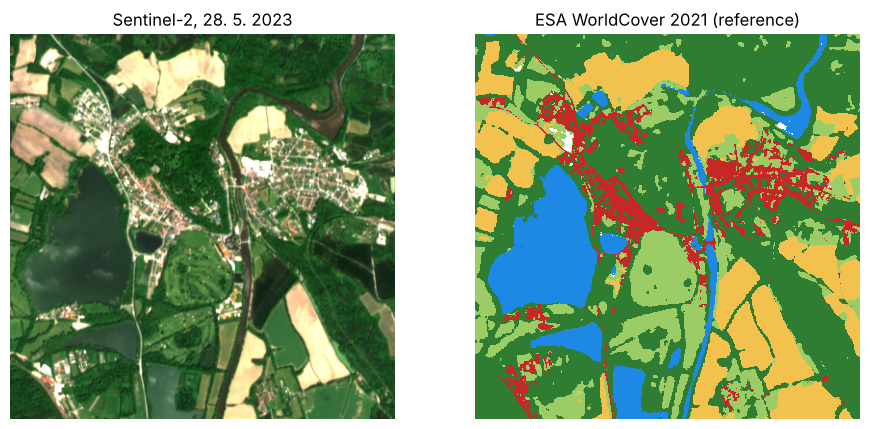

In [3]:
refl, scl, wl, grid, item = s2_window("S2B_33UVQ_20230528_0_L2A", 14.44, 49.05, 2000)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
CLASSES = {10: "les", 30: "louka", 40: "pole", 50: "zástavba", 80: "voda"}
COLORS = ["#2e7d32", "#9ccc65", "#f2c14e", "#c62828", "#1e88e5"]
FEAT = ["blue", "green", "red", "nir", "swir16", "swir22"]
X_img = np.dstack([refl[b] for b in FEAT])
ok = np.isin(scl, [4, 5, 6]) & np.isin(wc, list(CLASSES))
print("pixely podle třídy WorldCover:", {CLASSES[k]: int(((wc == k) & ok).sum()) for k in CLASSES})
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(np.clip(np.dstack([refl["red"], refl["green"], refl["blue"]]) / 0.15, 0, 1)); ax[0].set_title("Sentinel-2, 28. 5. 2023")
lab = np.full(wc.shape, np.nan); [lab.__setitem__(wc == k, i) for i, k in enumerate(CLASSES)]
ax[1].imshow(lab, cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); ax[1].set_title("ESA WorldCover 2021 (reference)")
for a in ax: a.axis("off")
plt.show()

## 2. Práh NDVI: dvě chyby proti sobě

Vegetace = les, louka a pole podle WorldCover, ostatní = zástavba a voda. Pro každý práh spočítáme, kolik vegetace přehlédneme a kolik ne-vegetace označíme jako vegetaci.

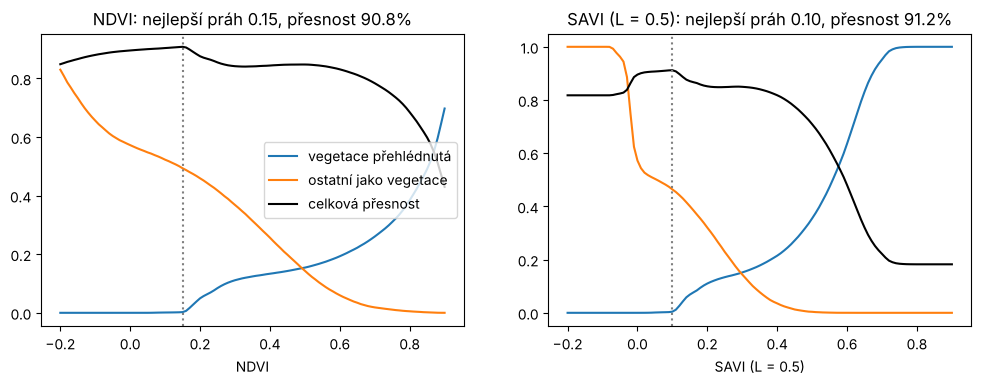

In [4]:
L = 0.5            # ◀ parametr: korekční faktor půdy pro SAVI (0 = NDVI, 0,5 obvykle, 1 řídký porost)
nir, red = refl["nir"], refl["red"]
ndvi = (nir - red) / (nir + red)
savi = (1 + L) * (nir - red) / (nir + red + L)
veg = np.isin(wc, [10, 30, 40])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (name, idx) in zip(ax, [("NDVI", ndvi), (f"SAVI (L = {L})", savi)]):
    thr = np.linspace(-0.2, 0.9, 111)
    miss = [np.mean(idx[ok & veg] < t_) for t_ in thr]          # vegetace přehlédnutá
    false = [np.mean(idx[ok & ~veg] >= t_) for t_ in thr]       # zástavba a voda jako vegetace
    total = [np.mean((idx[ok] >= t_) == veg[ok]) for t_ in thr]
    best = thr[int(np.argmax(total))]
    a.plot(thr, miss, label="vegetace přehlédnutá"); a.plot(thr, false, label="ostatní jako vegetace"); a.plot(thr, total, "k", label="celková přesnost")
    a.axvline(best, color="gray", ls=":"); a.set(xlabel=name, title=f"{name}: nejlepší práh {best:.2f}, přesnost {max(total):.1%}")
ax[0].legend(); plt.show()

> **✏️ Úkol 1.** Jaký práh NDVI je nejlepší a jaké chyby při něm zůstávají? Proč se nedá zbavit obou chyb současně? Které pixely „vegetace“ mají NDVI nízké (podívej se na pole: po žních je strniště, na jaře může být půda ještě holá) a proč je podle WorldCover počítáme jako vegetaci?

*Tvoje odpověď:* 

> **✏️ Úkol 2.** Porovnej NDVI a SAVI. Nastav `L = 0`, `0.25` a `1`. Jak se mění rozsah hodnot a nejlepší práh? Proč SAVI méně závisí na jasu půdy a proč v hustém porostu na tom skoro nezáleží?

*Tvoje odpověď:* 

## 3. Trénovací a testovací pixely

Sousední pixely jsou si podobné, takže náhodné rozdělení by přesnost nadsadilo. Trénujeme proto na severní polovině výřezu a testujeme na jižní.

In [5]:
n_train = 300      # ◀ parametr: počet trénovacích pixelů na třídu
rng = np.random.default_rng(1)
rows_ = np.arange(wc.shape[0])[:, None].repeat(wc.shape[1], 1)
def sample(mask, n):
    X, y = [], []
    for i, k in enumerate(CLASSES):
        idx = np.flatnonzero((mask & (wc == k)).ravel())
        idx = rng.choice(idx, min(n, len(idx)), replace=False)
        X.append(X_img.reshape(-1, len(FEAT))[idx]); y += [i] * len(idx)
    return np.vstack(X), np.array(y)
north, south = ok & (rows_ < wc.shape[0] // 2), ok & (rows_ >= wc.shape[0] // 2)
Xtr, ytr = sample(north, n_train)
Xte, yte = sample(south, 2000)
print("trénink:", np.bincount(ytr), "test:", np.bincount(yte))
names = list(CLASSES.values())

def report(model, title):
    pred = model.predict(Xte)
    cm = confusion_matrix(yte, pred, labels=range(5))
    pa, ua = np.diag(cm) / cm.sum(1), np.diag(cm) / np.maximum(cm.sum(0), 1)
    tab = pd.DataFrame(cm.astype(object), index=[f"ref {n}" for n in names], columns=names)
    tab["PA"] = pa.round(2); tab.loc["UA"] = list(ua.round(2)) + [""]
    print(f"{title}: celková přesnost test {np.mean(pred == yte):.1%}, trénink {model.score(Xtr, ytr):.1%}, kappa {cohen_kappa_score(yte, pred):.2f}")
    return tab

trénink: [300 300 300 300 300] test: [2000 2000 2000 2000 2000]


## 4. Minimální vzdálenost a maximální věrohodnost

In [6]:
mind = NearestCentroid().fit(Xtr, ytr)
display(report(mind, "Minimální vzdálenost"))
ml = QuadraticDiscriminantAnalysis(reg_param=1e-3).fit(Xtr, ytr)      # gaussovská maximální věrohodnost
display(report(ml, "Maximální věrohodnost"))

Minimální vzdálenost: celková přesnost test 68.8%, trénink 72.6%, kappa 0.61


,les,louka,pole,zástavba,voda,PA
ref les,1667,221,26,54,32,0.83
ref louka,426,1408,68,93,5,0.7
ref pole,1120,77,727,76,0,0.36
ref zástavba,41,142,652,1106,59,0.55
ref voda,23,0,1,5,1971,0.99
UA,0.51,0.76,0.49,0.83,0.95,


Maximální věrohodnost: celková přesnost test 72.5%, trénink 75.1%, kappa 0.66


,les,louka,pole,zástavba,voda,PA
ref les,1761,146,9,62,22,0.88
ref louka,569,1309,21,97,4,0.65
ref pole,1011,97,780,112,0,0.39
ref zástavba,66,153,290,1441,50,0.72
ref voda,30,0,0,7,1963,0.98
UA,0.51,0.77,0.71,0.84,0.96,


> **✏️ Úkol 3.** Čti chybovou matici maximální věrohodnosti: řádky jsou reference, sloupce výsledek. Která třída má nízkou přesnost zpracovatele (PA, je přehlížená) a která nízkou přesnost uživatele (UA, jiné třídy se do ní propadají)? Které dvojice tříd se nejvíc pletou a proč? Která z obou metod vyšla lépe? Maximální věrohodnost počítá s rozptylem a korelací pásem v každé třídě; proč přesto nemusí vyhrát (třídy nejsou normálně rozdělené, louka a les mají podobné spektrum, reference má chyby)?

*Tvoje odpověď:* 

## 5. Jak složitý model? k-NN a náhodný les

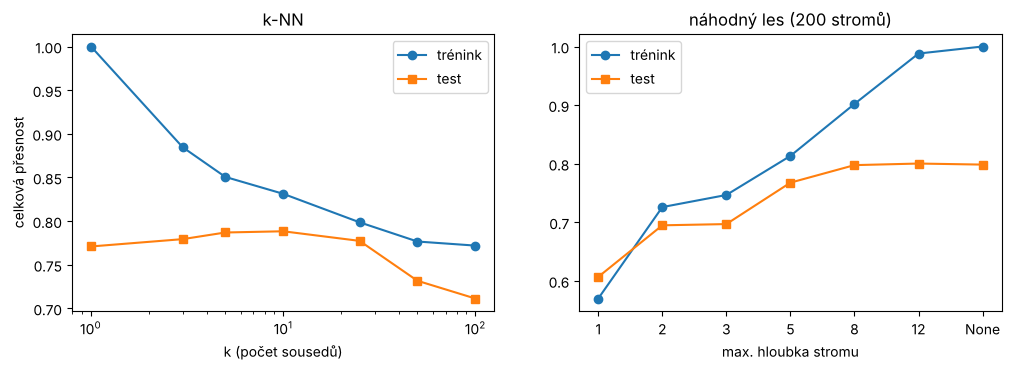

In [7]:
ks = [1, 3, 5, 10, 25, 50, 100]
depths = [1, 2, 3, 5, 8, 12, None]
acc = {"k-NN trénink": [], "k-NN test": [], "les trénink": [], "les test": []}
for k_ in ks:
    m = KNeighborsClassifier(k_).fit(Xtr, ytr); acc["k-NN trénink"].append(m.score(Xtr, ytr)); acc["k-NN test"].append(m.score(Xte, yte))
for d in depths:
    m = RandomForestClassifier(200, max_depth=d, random_state=0, n_jobs=-1).fit(Xtr, ytr)
    acc["les trénink"].append(m.score(Xtr, ytr)); acc["les test"].append(m.score(Xte, yte))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(ks, acc["k-NN trénink"], "o-", label="trénink"); ax[0].plot(ks, acc["k-NN test"], "s-", label="test")
ax[0].set(xscale="log", xlabel="k (počet sousedů)", ylabel="celková přesnost", title="k-NN"); ax[0].legend()
lbl = [str(d) for d in depths]
ax[1].plot(lbl, acc["les trénink"], "o-", label="trénink"); ax[1].plot(lbl, acc["les test"], "s-", label="test")
ax[1].set(xlabel="max. hloubka stromu", title="náhodný les (200 stromů)"); ax[1].legend(); plt.show()

> **✏️ Úkol 4.** Při k = 1 je přesnost na trénovacích pixelech 100 % nebo skoro 100 %. Proč to nic neznamená? Které k a jaká hloubka stromů dávají nejlepší testovací přesnost? Popiš, jak vypadá přeučení a nedoučení v obou grafech.

*Tvoje odpověď:* 

## 6. Neuronová síť a přeučení

Malá síť s jednou skrytou vrstvou. Učíme ji na málo pixelech a sledujeme přesnost na tréninku a testu po epochách.

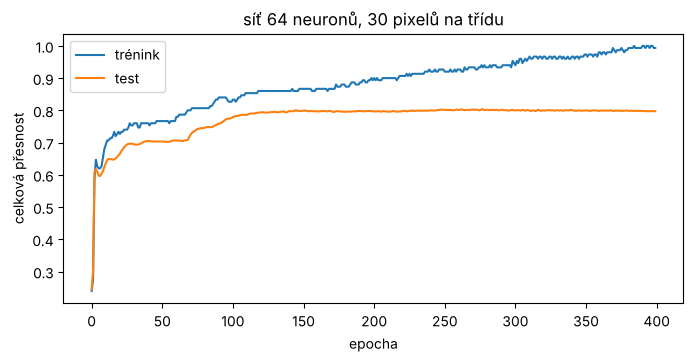

konec: trénink 99.3%, test 79.7%; nejlepší test 80.3% v epoše 262


In [8]:
hidden = 64        # ◀ parametr: počet skrytých neuronů
n_small = 30       # ◀ parametr: trénovacích pixelů na třídu (malý vzorek se snáz přeučí)
Xs, ys = sample(north, n_small)
mu, sd = Xs.mean(0), Xs.std(0)
net = MLPClassifier((hidden,), learning_rate_init=0.01, alpha=0.0, random_state=0)
hist = []
for epoch in range(400):
    net.partial_fit((Xs - mu) / sd, ys, classes=range(5))
    hist.append((net.score((Xs - mu) / sd, ys), net.score((Xte - mu) / sd, yte)))
hist = np.array(hist)
plt.figure(figsize=(8, 3.5)); plt.plot(hist[:, 0], label="trénink"); plt.plot(hist[:, 1], label="test")
plt.xlabel("epocha"); plt.ylabel("celková přesnost"); plt.title(f"síť {hidden} neuronů, {n_small} pixelů na třídu"); plt.legend(); plt.show()
print(f"konec: trénink {hist[-1, 0]:.1%}, test {hist[-1, 1]:.1%}; nejlepší test {hist[:, 1].max():.1%} v epoše {hist[:, 1].argmax()}")

> **✏️ Úkol 5.** Vyzkoušej `hidden` 4, 64 a 256 a `n_small` 30 a 300. Kdy se síť přeučí (trénink roste, test klesá nebo stagnuje)? Co by pomohlo: víc dat, menší síť, nebo zastavit učení dřív? Proč je rozdíl trénink–test u sítě větší než u maximální věrohodnosti?

*Tvoje odpověď:* 

## 7. Mapa výsledku

Náhodný les, hloubka 12: celková přesnost test 80.0%, trénink 98.8%, kappa 0.75


,les,louka,pole,zástavba,voda,PA
ref les,1558,313,26,68,35,0.78
ref louka,225,1636,18,117,4,0.82
ref pole,386,149,1347,113,5,0.67
ref zástavba,49,129,278,1513,31,0.76
ref voda,26,17,1,7,1949,0.97
UA,0.69,0.73,0.81,0.83,0.96,


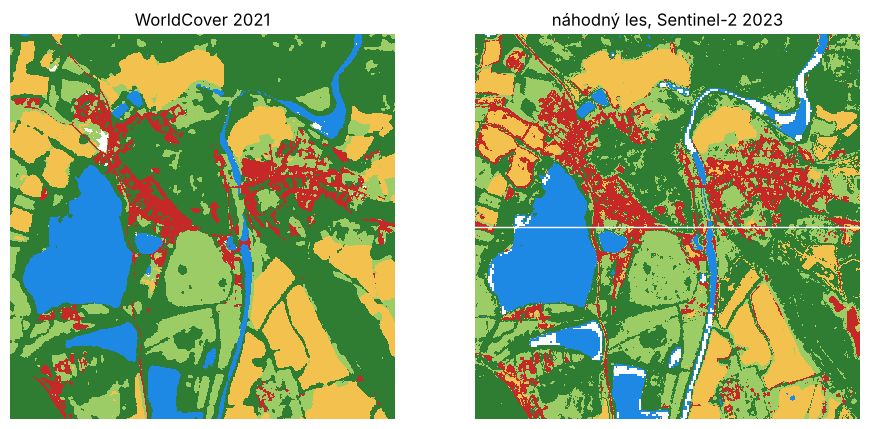

In [9]:
best = RandomForestClassifier(200, max_depth=12, random_state=0, n_jobs=-1).fit(Xtr, ytr)
display(report(best, "Náhodný les, hloubka 12"))
pred = best.predict(X_img.reshape(-1, len(FEAT))).reshape(wc.shape).astype(float)
pred[~np.isin(scl, [4, 5, 6])] = np.nan
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, (img, title) in zip(ax, [(lab, "WorldCover 2021"), (pred, "náhodný les, Sentinel-2 2023")]):
    a.imshow(img, cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); a.set_title(title); a.axis("off")
a.axhline(wc.shape[0] / 2, color="w", lw=1); plt.show()

> **✏️ Úkol 6.** Najdi místa, kde se mapa liší od WorldCover. Je chyba vždy v klasifikaci? Uvažuj o tom, že WorldCover je z roku 2021 a sám má chyby, že jeden snímek z jednoho dne nerozliší louku od pole s pícninou ani zelené obilí na jaře od trávy a že pixel 10 m na okraji lesa je směs. Jak bys přesnost hodnotil poctivě?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Porovnej své výsledky se spolužákem, který má notebook pro jiné místo (Roztoky, Brno, Hluboká nad Vltavou). Které třídy se jinde pletou víc a proč (roční doba snímku, druh krajiny, velikost polí)?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2023, ESA (L2A, Sen2Cor); registr AWS Open Data (`sentinel-cogs`), katalog Earth Search (Element 84). Volné užití s uvedením zdroje.
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Huete, A. R. (1988). A soil-adjusted vegetation index (SAVI). *Remote Sensing of Environment* 25, 295–309. https://doi.org/10.1016/0034-4257(88)90106-X
- Congalton, R. G., Green, K. (2019). *Assessing the Accuracy of Remotely Sensed Data: Principles and Practices*, 3. vyd. CRC Press.
- Pedregosa, F. a kol. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12, 2825–2830.

### Jak citovat

OpenSkyLab (2026). Od pixelu ke třídě: klasifikace Sentinelu-2 u Hluboké nad Vltavou [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/image_classification_hluboka_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*